In [ ]:
!pip install datasets scikit-learn pandas

In [ ]:
from datasets import load_dataset
dataset = load_dataset("dair-ai/emotion")
print(dataset)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [ ]:
import pandas as pd
train_df = pd.DataFrame(dataset['train'])
print(train_df.shape)
train_df.head(10)

(16000, 2)


,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3
5,ive been feeling a little burdened lately wasn...,0
6,ive been taking or milligrams or times recomme...,5
7,i feel as confused about life as a teenager or...,4
8,i have been with petronas for years i feel tha...,1
9,i feel romantic too,2


In [ ]:
label_names = dataset['train'].features['label'].names
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [ ]:
train_df['emotion'] = train_df['label'].apply(lambda x: label_names[x])
train_df.head(10)

,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger
5,ive been feeling a little burdened lately wasn...,0,sadness
6,ive been taking or milligrams or times recomme...,5,surprise
7,i feel as confused about life as a teenager or...,4,fear
8,i have been with petronas for years i feel tha...,1,joy
9,i feel romantic too,2,love


In [ ]:
train_df['emotion'].value_counts()

,count
emotion,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(train_df['text'])
print(X_train.shape)

(16000, 5000)


In [ ]:
print(train_df['text'].iloc[0])
print(X_train[0].toarray())

i didnt feel humiliated
[[0. 0. 0. ... 0. 0. 0.]]


In [ ]:
from sklearn.naive_bayes import MultinomialNB
y_train = train_df['label']
model = MultinomialNB()
model.fit(X_train, y_train)
print("Model trained successfully")

Model trained successfully


In [ ]:
test_df = pd.DataFrame(dataset['test'])
test_df['emotion'] = test_df['label'].apply(lambda x: label_names[x])
X_test = vectorizer.transform(test_df['text'])
y_test = test_df['label']
print(X_test.shape)

(2000, 5000)


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 71.55%


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.70      0.92      0.80       581
         joy       0.68      0.98      0.80       695
        love       1.00      0.11      0.20       159
       anger       0.94      0.39      0.55       275
        fear       0.90      0.38      0.54       224
    surprise       0.00      0.00      0.00        66

    accuracy                           0.72      2000
   macro avg       0.70      0.47      0.48      2000
weighted avg       0.75      0.72      0.66      2000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
full_df = pd.concat([
    pd.DataFrame(dataset['train']),
    pd.DataFrame(dataset['validation']),
    pd.DataFrame(dataset['test'])
], ignore_index=True)
full_df['emotion'] = full_df['label'].apply(lambda x: label_names[x])
print(full_df.shape)
full_df['emotion'].value_counts()

(20000, 3)


,count
emotion,
joy,6761
sadness,5797
anger,2709
fear,2373
love,1641
surprise,719


In [ ]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(
    full_df,
    test_size=0.2,
    random_state=42,
    stratify=full_df['label']
)
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (16000, 3)
Test: (4000, 3)


In [ ]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words='english'
)
X_train = vectorizer.fit_transform(train_df['text'])
X_test = vectorizer.transform(test_df['text'])
y_train = train_df['label']
y_test = test_df['label']
print(X_train.shape, X_test.shape)

(16000, 10000) (4000, 10000)


In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)
model.fit(X_train, y_train)
print("Model trained successfully")

Model trained successfully


In [ ]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")
print(classification_report(y_test, y_pred, target_names=label_names))

Accuracy: 89.78%
              precision    recall  f1-score   support

     sadness       0.95      0.91      0.93      1159
         joy       0.95      0.88      0.92      1352
        love       0.73      0.95      0.83       328
       anger       0.88      0.92      0.90       542
        fear       0.89      0.84      0.86       475
    surprise       0.67      0.95      0.79       144

    accuracy                           0.90      4000
   macro avg       0.85      0.91      0.87      4000
weighted avg       0.91      0.90      0.90      4000



In [ ]:
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=2
)
X_train = vectorizer.fit_transform(train_df['text'])
X_test = vectorizer.transform(test_df['text'])
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    C=5
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")
print(classification_report(y_test, y_pred, target_names=label_names))

Accuracy: 90.48%
              precision    recall  f1-score   support

     sadness       0.95      0.92      0.93      1159
         joy       0.94      0.91      0.92      1352
        love       0.77      0.91      0.83       328
       anger       0.89      0.92      0.90       542
        fear       0.89      0.86      0.87       475
    surprise       0.72      0.88      0.79       144

    accuracy                           0.90      4000
   macro avg       0.86      0.90      0.88      4000
weighted avg       0.91      0.90      0.91      4000



In [ ]:
import pickle
with open('emotion_model.pkl', 'wb') as f:
    pickle.dump(model, f)
with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
with open('label_names.pkl', 'wb') as f:
    pickle.dump(label_names, f)
print("All files saved")

All files saved


In [ ]:
from google.colab import files
files.download('emotion_model.pkl')
files.download('vectorizer.pkl')
files.download('label_names.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install datasets pandas scikit-learn

from datasets import load_dataset
import pandas as pd
from sklearn.model_selection import train_test_split

# Load and combine all 20,000 rows
dataset = load_dataset("dair-ai/emotion")
label_names = dataset['train'].features['label'].names

full_df = pd.concat([
    pd.DataFrame(dataset['train']),
    pd.DataFrame(dataset['validation']),
    pd.DataFrame(dataset['test'])
], ignore_index=True)
full_df['emotion'] = full_df['label'].apply(lambda x: label_names[x])

# Same 80/20 split you used for training (same random_state = same split)
train_df, test_df = train_test_split(
    full_df, test_size=0.2, random_state=42, stratify=full_df['label']
)

# Save to CSV
full_df.to_csv('emotion_full_dataset.csv', index=False)
train_df.to_csv('emotion_train_80.csv', index=False)
test_df.to_csv('emotion_test_20.csv', index=False)

# Download to your computer
from google.colab import files
files.download('emotion_full_dataset.csv')
files.download('emotion_train_80.csv')
files.download('emotion_test_20.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

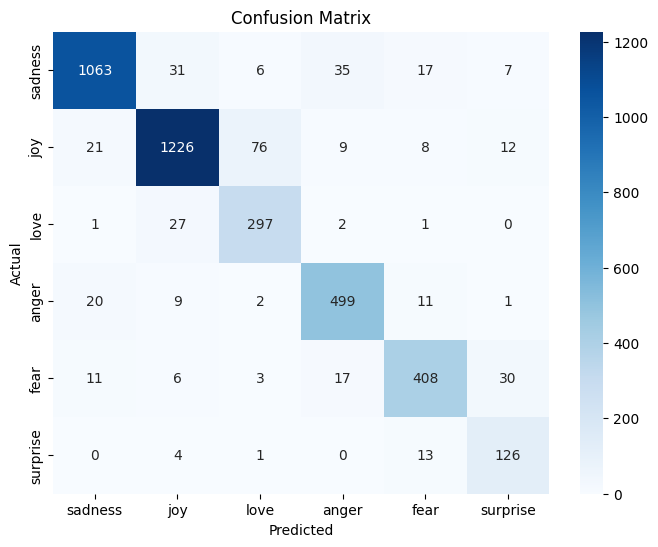

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()